# Learning thermal models for the heat-pump BEV

**The project question.** The NMPC uses a simplified physics model, the **COM**. The COM has 11 tuning
multipliers **γ (p1 … p11)**. Today they come from an interpolation table that was tuned at −5 and −10 °C.
We want a neural network that gives the COM better γ at *any* ambient temperature, trained so that the
COM's predicted states match the detailed Simulink model (the **HFM**).

**Words used in this notebook**

| term | meaning |
|---|---|
| **HFM** | high-fidelity model: the Simscape model in Simulink. Treated as the truth. |
| **COM** | control-oriented model: the 9-state model in `Source Files/dynamics_mexfreeNew.m`, used inside the NMPC |
| **γ (gamma)** | multipliers that scale terms in the COM (heat capacities, heat-transfer coefficients…). γ = 1 means "nominal". |
| **TNN** | thermal neural network (Kirchgässner, Wallscheid & Böcker 2023): a heat network whose parameters come from small neural networks |
| **profile** | one 1-hour simulation at one ambient temperature, 1 sample per second (3601 samples) |
| **30-s horizon error** | start from the true state, predict 30 s ahead (the NMPC horizon), measure the error. The main measure agreed with Prashant. |
| **free-run** | start once at t = 0 and predict the whole hour without ever resetting to the truth |

**The notebook has two parts**

- **Part A (sections 1–4, runs now).** Train a TNN that predicts our 6 temperatures directly.
  This checks that the data, the scaling and the training loop work. ⚠️ It does **not** give γ for the COM.
- **Part B (section 5, not finished).** γ-network → COM → compare with the HFM. This is the part that answers
  the project question. Missing: the COM rewritten in PyTorch (`com_xdot`).

**How to run:** *Run All* from the top. Training (section 3) takes about 2 minutes on the CPU.

## 0. Setup
Imports and global settings. If this cell fails with `No module named …`, VS Code is using the wrong Python
environment: pick the right kernel in the top-right corner.

In [1]:
import os, time, math
from pathlib import Path
import numpy as np
import scipy.io as sio          # reads MATLAB .mat files
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0); np.random.seed(0)   # same random start every time -> reproducible results
DEVICE = torch.device("cpu")              # the model is small: the CPU is as fast as a GPU here
DTYPE  = torch.float32
DATA    = Path("..") / "Data"             # old data:  SSY226-Group2/Data/tuning_data_<T>.mat
RESULTS = Path("..") / "Results"          # new data:  SSY226-Group2/Results/run_*/training_data_rule_T<T>.mat
print("torch", torch.__version__, "| data dir exists:", DATA.exists(), "| results dir exists:", RESULTS.exists())

torch 2.15.0+cpu | data dir exists: True | results dir exists: True


## 1. Data

We have **9 profiles**, one per ambient temperature, from two sources:

| files | ambient temperatures | contains a COM run? |
|---|---|---|
| `Data/tuning_data_<T>.mat` (old export) | −5, −7, −10 °C | yes (`States`): the COM simulated with nominal γ |
| `Results/run_*/training_data_rule_T<T>.mat` (`RunThermalComparison`, Nov 2026) | 0, −12, −15, −20, −25, −30 °C | no |

All of them are the same 1-hour drive cycle with the rule-based controller, sampled at 1 Hz.

**What the network gets (Part A)**

| group | signals | what it means |
|---|---|---|
| thermal nodes (6) | motor, inverter, DC-DC, battery, cabin interior, cabin air | the temperatures we **predict** |
| boundary temperatures (4) | ambient, inverter-coolant inlet, heater-coolant outlet, vent air | temperatures we **give** it, taken from the HFM |
| observables (12) | compressor speed, blower flow, pump speed, coolant flows, battery current, heat loads, heater command, refrigerant pressures | other measured signals, each divided by a typical value (`OBS`) so it lies around 0–1 |

⚠️ Because the boundary temperatures come from the HFM, the TNN is partly handed the answer. The COM has to
work those out itself. That is why Part A's comparison with the COM is not fair (see section 4).

**Units.** Everything is loaded in °C, MPa, rpm, kg/s, W and A. Section 1d then divides the temperatures by 100
for the network.

**Known differences between old and new data** (not unit errors):
- the new runs have the pumps at 1200 rpm, the old ones at 900 rpm;
- `htxClntMf` is not in the new export; we use `motClntMf`, which was identical in the old data;
- in the new data, `cabIntT` is a plain average of glass/doors/roof (the COM uses a mass-weighted one);
- vehicle speed is in the new export but not in the old files, so it is not used yet.

### 1a. Signal names and scales, and the loader for the old files

In [2]:
# The 6 temperatures the network predicts, and the 4 temperatures it is given
NODE_NAMES = ["motT", "invT", "dcdcT", "batT", "cabIntT", "cabAirT"]
BND_NAMES  = ["Tamb", "clntInvTin", "heaterClntTout", "ventAirT"]

# Observables: name -> typical value. Each signal is divided by its typical value so the network sees ~0..1.
# (Only for the network: this is scaling, not a unit change.)
OBS = {
    "compNrpm":    4500,   # compressor speed [rpm]
    "cabAirMfIn":  0.14,   # blower air mass flow [kg/s]
    "motPumpNrpm": 900,    # motor-loop pump speed [rpm]
    "motClntMf":   0.33,   # motor-loop coolant mass flow [kg/s]
    "htxClntMf":   0.33,   # heat-exchanger coolant mass flow [kg/s]
    "batImeas":    175,    # battery current [A]
    "motQmeas":    4300,   # motor heat generation [W]
    "invQmeas":    240,    # inverter heat generation [W]
    "dcdcQmeas":   240,    # DC-DC heat generation [W]
    "heaterCmd":   1.0,    # heater command [0..1]
    "compPinMpa":  0.3,    # compressor inlet pressure [MPa]
    "compPoutMpa": 4.0,    # compressor outlet pressure [MPa]
}

def K2C(x):
    """kelvin -> °C"""
    return x - 273.15

def load_profile(T):
    """Load an OLD file Data/tuning_data_<T>.mat (T = 5 means -5 °C).

    Returns a dict with
      T     ambient temperature [°C]
      nodes [3601, 6] HFM temperatures to predict [°C]
      bnd   [3601, 4] boundary temperatures given to the network [°C]
      obs   [3601, 12] observables, already divided by their OBS scale
      com   [3601, 6] the COM run with nominal γ [°C] (baseline to beat)
    Some old signals are stored in kelvin, so K2C converts them to °C.
    Careful: heaterClntToutMeasC is in kelvin despite its name.
    """
    d = sio.loadmat(DATA / f"tuning_data_{T}.mat", squeeze_me=True, struct_as_record=False)
    r, S = d["resampled"], d["States"]        # r = HFM signals, S = COM states (9 x 3601, kelvin / Pa)
    tamb = float(d["envTemp"])
    nodes = np.stack([r.motTmeasC, r.invTmeasC, r.dcdcTmeasC, r.batTmeasC,
                      K2C(r.cabIntTInK), r.cabAirTmeasC], 1)
    bnd = np.stack([np.full_like(r.motTmeasC, tamb), r.clntInvTInC,
                    K2C(r.heaterClntToutMeasC), K2C(r.innerCondAirToutK)], 1)
    obs = np.stack([np.asarray(getattr(r, k), float) / s for k, s in OBS.items()], 1)
    # COM states 0,1,2,4,7,8 = motT, invT, dcdcT, batT, cabIntT, cabAirT (3 = SOC, 5-6 = pressures are skipped)
    com = np.stack([K2C(S[0]), K2C(S[1]), K2C(S[2]), K2C(S[4]), K2C(S[7]), K2C(S[8])], 1)
    return dict(T=tamb, nodes=nodes, bnd=bnd, obs=np.nan_to_num(obs), com=com)

### 1b. Loader for the new files
Maps the new export onto exactly the same signals, units and scales as `load_profile`.

In [3]:
# Name in OBS (old files)  ->  field name in the new training_data files
NEW2OLD = {
    "compNrpm": "compNrpm", "cabAirMfIn": "cabAirMfIn_kgs", "motPumpNrpm": "motPumpNrpm",
    "motClntMf": "motClntMf_kgs",
    "htxClntMf": "motClntMf_kgs",   # not exported; equal to motClntMf in the old data (max diff 3e-5 kg/s)
    "batImeas": "batI_A", "motQmeas": "motQgen_W", "invQmeas": "invQgen_W", "dcdcQmeas": "dcdcQgen_W",
    "heaterCmd": "heaterCmd", "compPinMpa": "compPin_MPa", "compPoutMpa": "compPout_MPa",
}

def load_new_profile(path):
    """Load a NEW file Results/run_*/training_data_rule_T<T>.mat. Same output as load_profile, but com=None
    because these files contain no COM run. All temperatures are already in °C, pressures in MPa."""
    d = sio.loadmat(path, squeeze_me=True, struct_as_record=False)["trainingData"]
    tamb = float(d.T_amb_C)
    nodes = np.stack([d.motT_C, d.invT_C, d.dcdcT_C, d.batT_C, d.cabIntT_C, d.cabAirT_C], 1)
    bnd = np.stack([np.full_like(d.motT_C, tamb), d.clntInvTin_C, d.heaterClntTout_C, d.ventAirT_C], 1)
    obs = np.stack([np.asarray(getattr(d, NEW2OLD[k]), float) / s for k, s in OBS.items()], 1)
    return dict(T=tamb, nodes=nodes, bnd=bnd, obs=np.nan_to_num(obs), com=None)

### 1c. Load all 9 profiles, check the units, and look at one
`profiles` is a dict keyed by the ambient temperature **without the minus sign**: `profiles[12]` is −12 °C.

In [4]:
profiles = {T: load_profile(T) for T in (5, 7, 10)}             # old files: -5, -7, -10 °C

for f in sorted(RESULTS.glob("run_*/training_data_rule_T*.mat")):  # new files: 0 ... -30 °C
    q = load_new_profile(f)
    profiles[int(round(abs(q["T"])))] = q

for T in sorted(profiles):
    p = profiles[T]
    src_ = "old" if p["com"] is not None else "new"
    print(f"Tamb={p['T']:+.0f} °C  ({src_})  N={len(p['nodes'])}  nodes range {p['nodes'].min():.1f}..{p['nodes'].max():.1f} °C")

Tamb=+0 °C  (new)  N=3601  nodes range 0.0..40.8 °C
Tamb=-5 °C  (old)  N=3601  nodes range -5.0..37.4 °C
Tamb=-7 °C  (old)  N=3601  nodes range -7.0..36.2 °C
Tamb=-10 °C  (old)  N=3601  nodes range -10.0..34.9 °C
Tamb=-12 °C  (new)  N=3601  nodes range -12.0..33.8 °C
Tamb=-15 °C  (new)  N=3601  nodes range -15.0..32.2 °C
Tamb=-20 °C  (new)  N=3601  nodes range -20.0..29.9 °C
Tamb=-25 °C  (new)  N=3601  nodes range -25.0..28.9 °C
Tamb=-30 °C  (new)  N=3601  nodes range -30.0..28.9 °C


In [5]:
# Unit check: old and new profiles must look alike. A unit mistake shows up immediately:
#  - kelvin instead of °C -> temperatures start near 250-270 instead of at Tamb
#  - Pa instead of MPa    -> scaled pressures around 1e6
#  - wrong flow/power unit -> scaled observables far above 2
# (Values slightly above 1 are real: the new runs use 1200-rpm pumps and more blower flow at -30 °C.)
def check_units(p):
    problems = []
    if not np.allclose(p["nodes"][0], p["T"], atol=0.5):
        problems.append(f"node temperatures do not start at Tamb: {np.round(p['nodes'][0], 1)}")
    if not np.allclose(p["bnd"][0], p["T"], atol=0.5):
        problems.append(f"boundary temperatures do not start at Tamb: {np.round(p['bnd'][0], 1)}")
    if p["nodes"].min() < -40 or p["nodes"].max() > 80:
        problems.append(f"node temperatures outside -40..80 °C: {p['nodes'].min():.1f}..{p['nodes'].max():.1f}")
    if p["bnd"].min() < -40 or p["bnd"].max() > 80:
        problems.append(f"boundary temperatures outside -40..80 °C: {p['bnd'].min():.1f}..{p['bnd'].max():.1f}")
    for name, m in zip(OBS, p["obs"].max(0)):
        if m > 2.0:
            problems.append(f"obs '{name}' scaled max {m:.2f} > 2.0 (wrong unit?)")
    if np.isnan(p["nodes"]).any() or np.isnan(p["bnd"]).any():
        problems.append("NaN in nodes/boundaries")
    return problems

print(f"{'key':>4} {'Tamb':>5}  {'nodes °C':>13}  {'bnd °C':>13}  max scaled obs   status")
for key in sorted(profiles):
    p = profiles[key]
    probs = check_units(p)
    print(f"{key:>4} {p['T']:+5.0f}  {p['nodes'].min():6.1f}..{p['nodes'].max():5.1f}  "
          f"{p['bnd'].min():6.1f}..{p['bnd'].max():5.1f}  {p['obs'].max():6.2f}         "
          f"{'OK' if not probs else 'CHECK'}")
    for pr in probs:
        print("        -", pr)

 key  Tamb       nodes °C         bnd °C  max scaled obs   status
   0    +0     0.0.. 40.8     0.0.. 52.0    1.33         OK
   5    -5    -5.0.. 37.4    -7.7.. 53.3    1.01         OK
   7    -7    -7.0.. 36.2    -8.2.. 52.2    1.00         OK
  10   -10   -10.0.. 34.9   -10.0.. 49.8    1.00         OK
  12   -12   -12.0.. 33.8   -12.0.. 47.9    1.33         OK
  15   -15   -15.0.. 32.2   -15.0.. 46.4    1.33         OK
  20   -20   -20.0.. 29.9   -20.0.. 43.8    1.36         OK
  25   -25   -25.0.. 28.9   -25.0.. 37.3    1.44         OK
  30   -30   -30.0.. 28.9   -30.0.. 28.6    1.51         OK


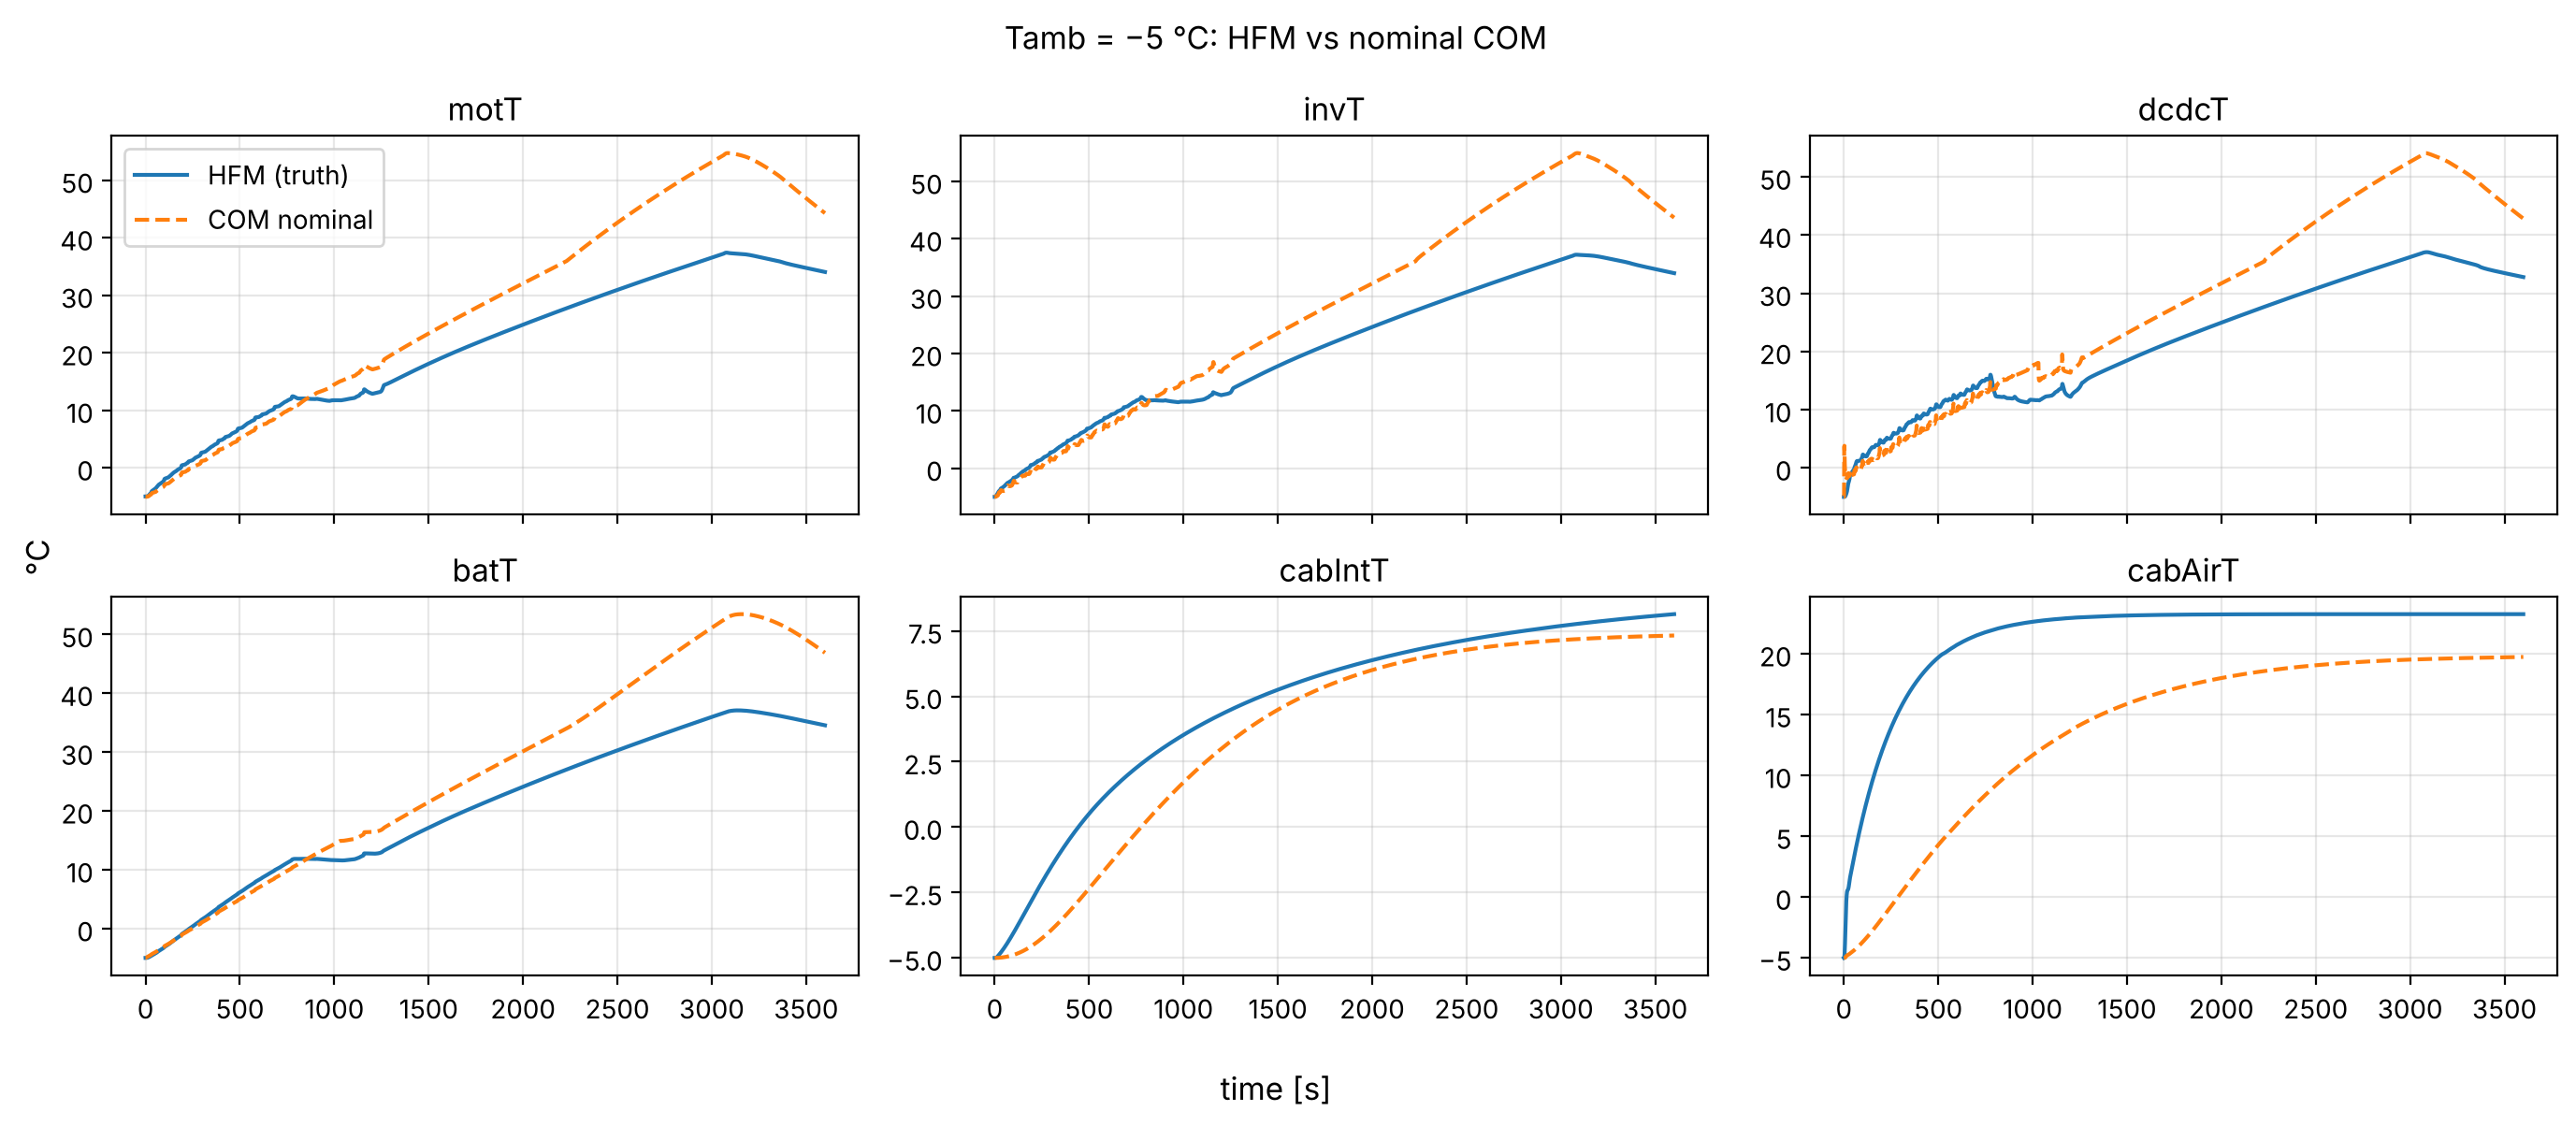

In [6]:
# Look at the data before training: HFM (truth) vs the COM with nominal γ at -5 °C.
# The gap between the two curves is what the project tries to close.
fig, ax = plt.subplots(2, 3, figsize=(14, 6), sharex=True)
p = profiles[5]; t = np.arange(len(p["nodes"]))
for i, a in enumerate(ax.flat):
    a.plot(t, p["nodes"][:, i], label="HFM (truth)")
    a.plot(t, p["com"][:, i], "--", label="COM nominal")
    a.set_title(NODE_NAMES[i]); a.grid(alpha=.3)
ax[0, 0].legend(); fig.supxlabel("time [s]"); fig.supylabel("°C"); fig.suptitle("Tamb = −5 °C: HFM vs nominal COM")
plt.tight_layout()

### 1d. Scale for the network and split into training / test
Neural networks learn best with numbers around −1…1, so the temperatures are divided by 100
(−30…+40 °C becomes −0.3…+0.4), as in the TNN paper. All results are multiplied back by 100 to report °C.

The test temperatures are never used for training, so the test shows how well the model works at
**ambient temperatures it has not seen**.

In [7]:
SCALE_T = 100.0   # temperatures [°C] / 100 -> network units

def to_tensors(p):
    """One profile -> (x: nodes [N, 6], b: boundaries [N, 4], xi: observables [N, 12]) as torch tensors."""
    x  = torch.tensor(p["nodes"] / SCALE_T, dtype=DTYPE)
    b  = torch.tensor(p["bnd"]   / SCALE_T, dtype=DTYPE)
    xi = torch.tensor(p["obs"],              dtype=DTYPE)   # already scaled by OBS
    return x, b, xi

# Train on 0, -5, -10, -15, -20, -30 °C; test on the unseen -7, -12, -25 °C.
# Keep 7 FIRST in TEST_T: the plots in section 4 use the first test profile and the COM run stored in the old -7 °C file.
TRAIN_T, TEST_T = (0, 5, 10, 15, 20, 30), (7, 12, 25)

# Stack the profiles: shapes are [number of profiles, 3601 time steps, number of signals]
Xtr, Btr, Otr = map(lambda z: torch.stack(z), zip(*[to_tensors(profiles[T]) for T in TRAIN_T]))
Xte, Bte, Ote = map(lambda z: torch.stack(z), zip(*[to_tensors(profiles[T]) for T in TEST_T]))
print("train", tuple(Xtr.shape), "test", tuple(Xte.shape))

train (6, 3601, 6) test (3, 3601, 6)


## 2. Part A: the TNN model

The TNN is a **heat network**: each of the 6 temperatures is a node, every pair of nodes is connected by a
thermal conductance, and heat flows from warm to cold. Each second the temperature of node *i* is updated by
(paper Eq. 8):

$$\hat\vartheta_i[k+1] = \hat\vartheta_i[k] + T_s\,\kappa_i\Big(\pi_i[k] + \sum_{j}(\vartheta_j-\hat\vartheta_i)\,\gamma_{ij}[k]\Big)$$

In words: *new temperature = old temperature + 1 s × (1 / heat capacity) × (heat generated + heat flowing in from all other nodes)*.

| symbol | meaning | where it comes from |
|---|---|---|
| $\gamma_{ij}$ | conductance between nodes *i* and *j* (how easily heat flows) | neural network `gamma_net`, always ≥ 0 |
| $\pi_i$ | heat generated or removed at node *i* | neural network `pi_net` |
| $\kappa_i$ | 1 / heat capacity of node *i* | one trainable number per node, $\kappa = 10^{\theta_c}$ |
| $\vartheta_j$ | temperature of node *j*: one of the 6 predicted or one of the 4 given | |

Both networks see the same inputs $\zeta$: the current 6 temperatures, the 4 boundary temperatures and the
12 observables. So the conductances and heat flows change with the operating point.

Note: the TNN's γ are *its own* conductances, not the COM's p1–p11.

In [8]:
def mlp(n_in, n_out, hidden=(32, 32), act=nn.Tanh, out_act=None):
    """A small fully connected network: n_in -> 32 -> 32 -> n_out, tanh in between."""
    layers, d = [], n_in
    for h in hidden:
        layers += [nn.Linear(d, h), act()]; d = h
    layers += [nn.Linear(d, n_out)]
    if out_act is not None: layers += [out_act()]
    return nn.Sequential(*layers)

class TNNCell(nn.Module):
    """One time step of the heat network (paper Eq. 8)."""
    def __init__(self, m, n, n_obs, Ts=1.0, hidden=(32, 32)):
        # m = 6 predicted nodes, n = 4 boundary nodes, n_obs = 12 observables, Ts = 1 s step
        super().__init__()
        self.m, self.n, self.Ts = m, n, Ts
        N = m + n                                            # 10 nodes in total
        iu = torch.triu_indices(N, N, offset=1)              # all node pairs (i < j): 45 pairs
        self.register_buffer("iu", iu)
        n_pairs = iu.shape[1]
        n_in = m + n + n_obs                                 # network input zeta: 6 + 4 + 12 = 22 numbers
        self.gamma_net = mlp(n_in, n_pairs, hidden, out_act=nn.Softplus)  # one conductance per pair, softplus keeps it >= 0
        self.pi_net    = mlp(n_in, m, hidden)                # one heat source per predicted node (can be + or -)
        self.theta_c   = nn.Parameter(torch.full((m,), -1.0))   # kappa = 10**theta_c, starts at 0.1

    def conductance_matrix(self, g):
        """45 pair conductances -> symmetric 10x10 matrix (G[i,j] = G[j,i], zero diagonal)."""
        B, N = g.shape[0], self.m + self.n
        G = g.new_zeros(B, N, N)
        G[:, self.iu[0], self.iu[1]] = g
        return G + G.transpose(1, 2)

    def forward(self, x, bnd, xi):
        # x: current 6 temperatures, bnd: 4 boundary temperatures, xi: 12 observables (all for one time step)
        zeta = torch.cat([x, bnd, xi], -1)                   # network input
        g    = self.gamma_net(zeta)                          # conductances [B, 45]
        G    = self.conductance_matrix(g)                    # [B, 10, 10]
        all_T = torch.cat([x, bnd], -1)                      # all 10 temperatures
        dT    = all_T.unsqueeze(1) - x.unsqueeze(2)          # temperature differences T_j - T_i  [B, 6, 10]
        heat  = (G[:, :self.m, :] * dT).sum(-1)              # heat flowing into each predicted node
        kappa = 10.0 ** self.theta_c                         # 1 / heat capacity
        x_next = x + self.Ts * kappa * (self.pi_net(zeta) + heat)   # Eq. 8
        return x_next, g

class TNN(nn.Module):
    """Repeats TNNCell over time: starts at x0 and predicts one step at a time."""
    def __init__(self, *a, **k):
        super().__init__(); self.cell = TNNCell(*a, **k)
    def forward(self, x0, bnd, xi):
        # x0: start temperatures [B, 6]; bnd, xi: inputs over L steps [B, L, .]
        # returns predicted temperatures for steps 1..L  [B, L, 6]
        x, out = x0, []
        for k in range(bnd.shape[1]):
            x, _ = self.cell(x, bnd[:, k], xi[:, k])         # the prediction is fed back in: no truth used
            out.append(x)
        return torch.stack(out, 1)

model = TNN(m=len(NODE_NAMES), n=len(BND_NAMES), n_obs=len(OBS)).to(DEVICE)
print(f"trainable parameters: {sum(p.numel() for p in model.parameters()):,}")

trainable parameters: 5,273


## 3. Training

The model predicts a whole profile step by step, and the error against the HFM is minimised.
Running back-propagation through all 3600 steps at once would be slow and unstable, so the hour is cut into
chunks of 300 s (**truncated back-propagation through time**, TBPTT). The predicted state is carried from one
chunk to the next, but gradients stop at the chunk border. All training profiles are run in parallel.

epoch   0  train RMSE   7.54 °C   lr 3.0e-03       2s


epoch   5  train RMSE   2.19 °C   lr 3.0e-03       9s


epoch  10  train RMSE   1.69 °C   lr 3.0e-03      15s


epoch  15  train RMSE   1.25 °C   lr 3.0e-03      22s


epoch  20  train RMSE   0.88 °C   lr 3.0e-03      28s


epoch  25  train RMSE   0.67 °C   lr 3.0e-03      35s


... (3 outputs left out)

epoch  45  train RMSE   0.44 °C   lr 3.0e-03      62s


epoch  50  train RMSE   0.55 °C   lr 3.0e-03      68s


epoch  55  train RMSE   0.58 °C   lr 1.5e-03      75s


epoch  59  train RMSE   0.39 °C   lr 1.5e-03      80s


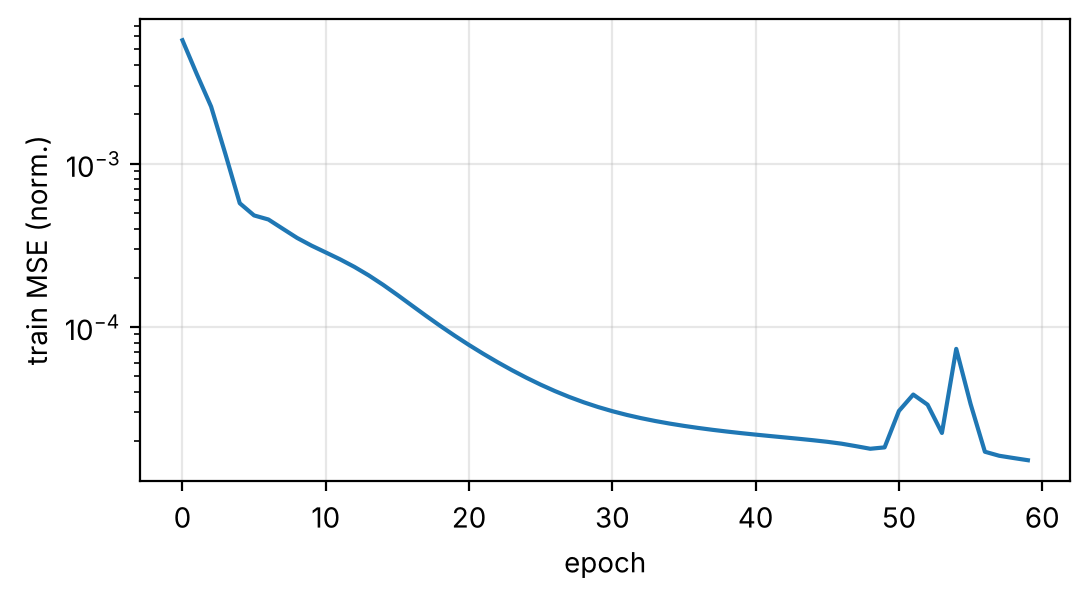

In [9]:
EPOCHS = 60      # passes over the training data
TBPTT  = 300     # chunk length [s] for back-propagation
LR     = 3e-3    # learning rate

opt   = torch.optim.NAdam(model.parameters(), lr=LR)
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=5)   # halve LR if the loss stops improving
lossf = nn.MSELoss()
hist = []
t0 = time.time()
for ep in range(EPOCHS):
    model.train(); x = Xtr[:, 0]; ep_loss = 0.0; n_chunks = 0       # start every profile at its true t = 0 state
    for s in range(0, Xtr.shape[1] - 1, TBPTT):
        e = min(s + TBPTT, Xtr.shape[1] - 1)
        pred = model(x, Btr[:, s:e], Otr[:, s:e])          # predict steps s+1 .. e
        loss = lossf(pred, Xtr[:, s + 1:e + 1])            # compare with the HFM
        opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)  # cap the gradient size to keep training stable
        opt.step()
        x = pred[:, -1].detach()                           # carry the predicted state on, cut the gradient
        ep_loss += loss.item(); n_chunks += 1
    ep_loss /= n_chunks; hist.append(ep_loss); sched.step(ep_loss)
    if ep % 5 == 0 or ep == EPOCHS - 1:
        rmse_C = math.sqrt(ep_loss) * SCALE_T              # back to °C for printing
        print(f"epoch {ep:3d}  train RMSE {rmse_C:6.2f} °C   lr {opt.param_groups[0]['lr']:.1e}   {time.time()-t0:5.0f}s")
plt.figure(figsize=(6, 3)); plt.semilogy(hist); plt.xlabel("epoch"); plt.ylabel("train MSE (norm.)"); plt.grid(alpha=.3)

## 4. Evaluation on the unseen ambient temperatures (−7, −12, −25 °C)

**(a) 30-s horizon error**: the main measure agreed with Prashant. Every 30 s, start from the true state,
predict 30 s ahead (like the NMPC does), and average the error over all these windows.

**(b) Free-run**: start once at t = 0 and predict the whole hour, compared with the COM run (nominal γ)
stored in the old −7 °C file. The plots use −7 °C because it is the only test profile with a COM run.

> ⚠️ **Not a fair comparison yet.** The TNN is given the HFM's coolant and vent-air temperatures as inputs, and
> these are very close to the temperatures it predicts. The COM has to compute them itself from the compressor,
> pumps and heat exchangers. A hint: the TNN's 1-hour free-run error is almost the same as its 30-s error, because
> those inputs keep correcting it. So Part A shows that the data and training work. The comparison that counts
> for the report is Part B: the same COM with learned γ vs γ from the interpolation table.

30-s horizon RMSE  motT      0.188 °C
30-s horizon RMSE  invT      0.149 °C
30-s horizon RMSE  dcdcT     0.307 °C
30-s horizon RMSE  batT      0.313 °C
30-s horizon RMSE  cabIntT   0.428 °C
30-s horizon RMSE  cabAirT   0.500 °C

Tamb = - 7 °C   30-s horizon RMSE (mean over nodes)  0.314 °C   motT=0.19  invT=0.15  dcdcT=0.31  batT=0.31  cabIntT=0.43  cabAirT=0.50
Tamb = -12 °C   30-s horizon RMSE (mean over nodes)  0.472 °C   motT=0.17  invT=0.21  dcdcT=0.24  batT=0.28  cabIntT=1.03  cabAirT=0.90
Tamb = -25 °C   30-s horizon RMSE (mean over nodes)  0.506 °C   motT=0.32  invT=0.28  dcdcT=0.32  batT=0.35  cabIntT=0.72  cabAirT=1.04


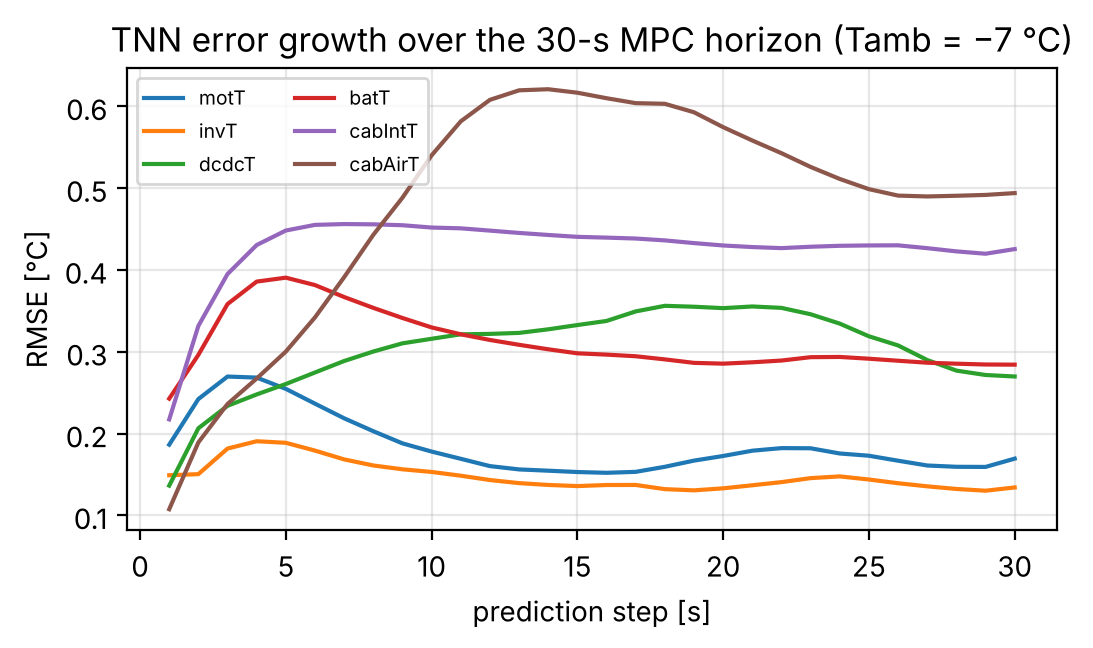

In [10]:
H = 30   # NMPC horizon [s]

@torch.no_grad()
def horizon_rmse(model, X, B, O, H=30):
    """30-s horizon RMSE for the FIRST profile in X. Returns (RMSE per node, RMSE per horizon step), in °C."""
    starts = torch.arange(0, X.shape[1] - H, H)              # window start times: 0, 30, 60, ...
    x0 = X[0, starts]                                         # true state at each start   [W, 6]
    idx = starts[:, None] + torch.arange(H)[None]             # time indices of each window [W, H]
    pred = model(x0, B[0, idx], O[0, idx])                    # all windows in parallel     [W, H, 6]
    true = X[0, idx + 1]
    err = (pred - true) * SCALE_T                             # back to °C
    return err.pow(2).mean((0, 1)).sqrt(), err.pow(2).mean(0).sqrt()

model.eval()
rmse_node, rmse_step = horizon_rmse(model, Xte, Bte, Ote, H)   # first test profile = -7 °C
for n, v in zip(NODE_NAMES, rmse_node): print(f"30-s horizon RMSE  {n:8s} {v:6.3f} °C")
plt.figure(figsize=(6, 3)); plt.plot(np.arange(1, H + 1), rmse_step.numpy())
plt.xlabel("prediction step [s]"); plt.ylabel("RMSE [°C]"); plt.legend(NODE_NAMES, fontsize=7, ncol=2); plt.grid(alpha=.3)
plt.title("TNN error growth over the 30-s MPC horizon (Tamb = −7 °C)")

# The same measure for every unseen test temperature
print()
for j, T in enumerate(TEST_T):
    r_node, _ = horizon_rmse(model, Xte[j:j+1], Bte[j:j+1], Ote[j:j+1], H)
    print(f"Tamb = -{T:>2} °C   30-s horizon RMSE (mean over nodes) {r_node.mean():6.3f} °C   "
          + "  ".join(f"{n}={v:.2f}" for n, v in zip(NODE_NAMES, r_node)))

node      COM nominal      TNN   (free-run RMSE, °C)
motT             8.71     0.19
invT             8.88     0.15
dcdcT            8.58     0.31
batT             8.04     0.32
cabIntT          1.29     0.44
cabAirT          8.75     0.55


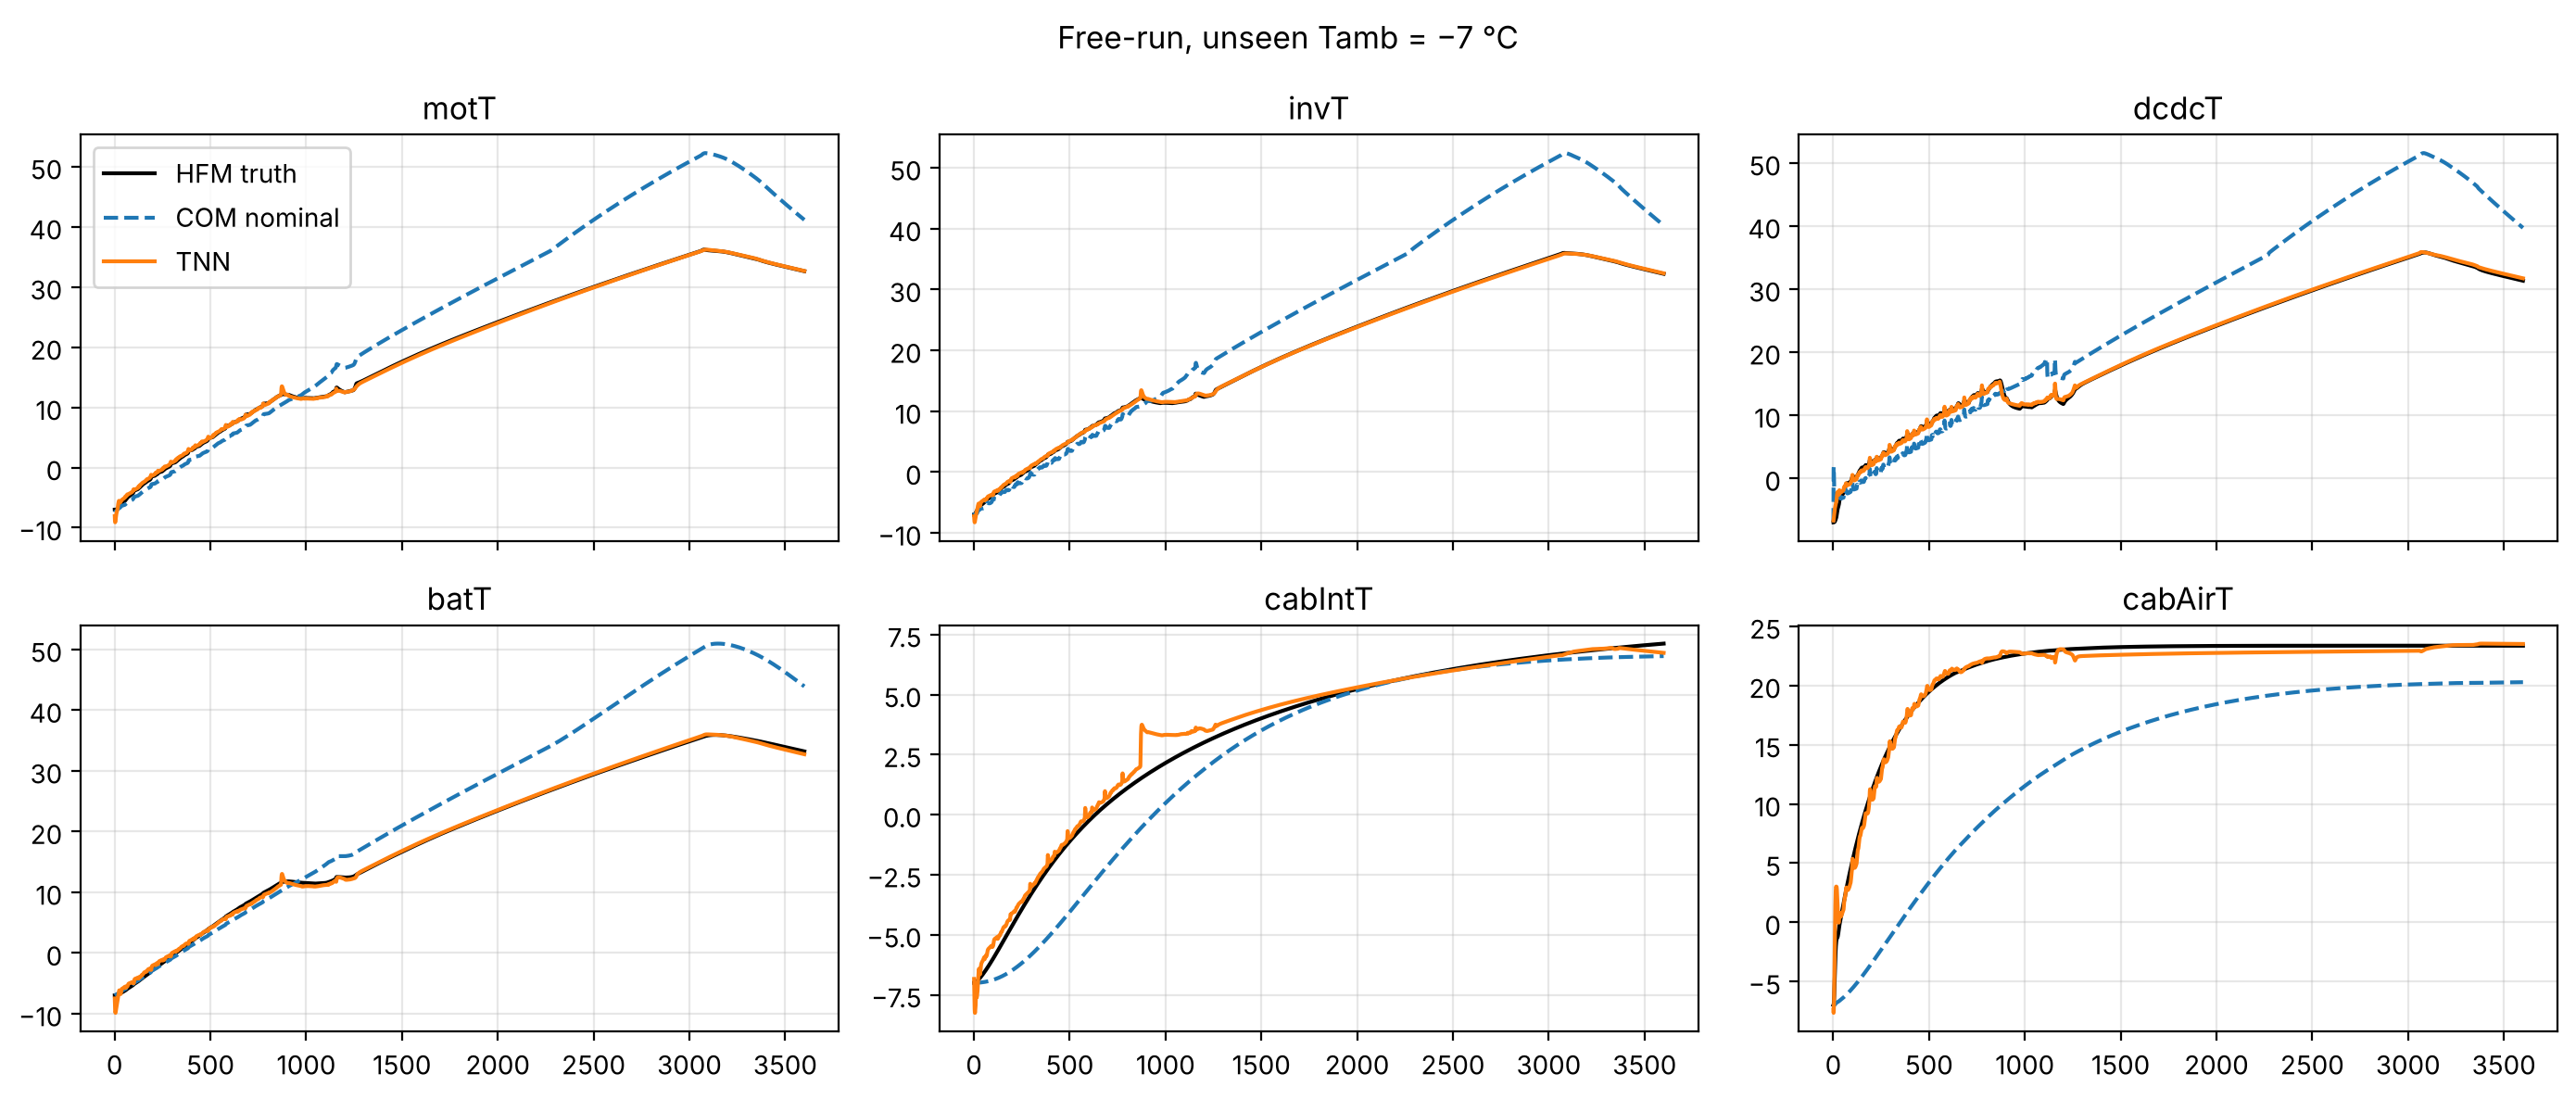

In [11]:
# (b) Free-run over the whole hour at -7 °C: HFM vs COM (nominal γ) vs TNN
with torch.no_grad():
    free = model(Xte[:, 0], Bte[:, :-1], Ote[:, :-1])[0].numpy() * SCALE_T   # [0] = first test profile (-7 °C)
truth = profiles[7]["nodes"][1:]; com = profiles[7]["com"][1:]
t = np.arange(1, len(truth) + 1)
fig, ax = plt.subplots(2, 3, figsize=(14, 6), sharex=True)
for i, a in enumerate(ax.flat):
    a.plot(t, truth[:, i], "k", lw=1.5, label="HFM truth")
    a.plot(t, com[:, i], "--", label="COM nominal")
    a.plot(t, free[:, i], label="TNN")
    a.set_title(NODE_NAMES[i]); a.grid(alpha=.3)
ax[0, 0].legend(); fig.suptitle("Free-run, unseen Tamb = −7 °C"); plt.tight_layout()

def rmse(a, b): return np.sqrt(((a - b) ** 2).mean(0))      # RMSE per node over the whole hour
print(f"{'node':8s} {'COM nominal':>12s} {'TNN':>8s}   (free-run RMSE, °C)")
for n, c, m_ in zip(NODE_NAMES, rmse(com, truth), rmse(free, truth)):
    print(f"{n:8s} {c:12.2f} {m_:8.2f}")

saved tnn_partA.pt


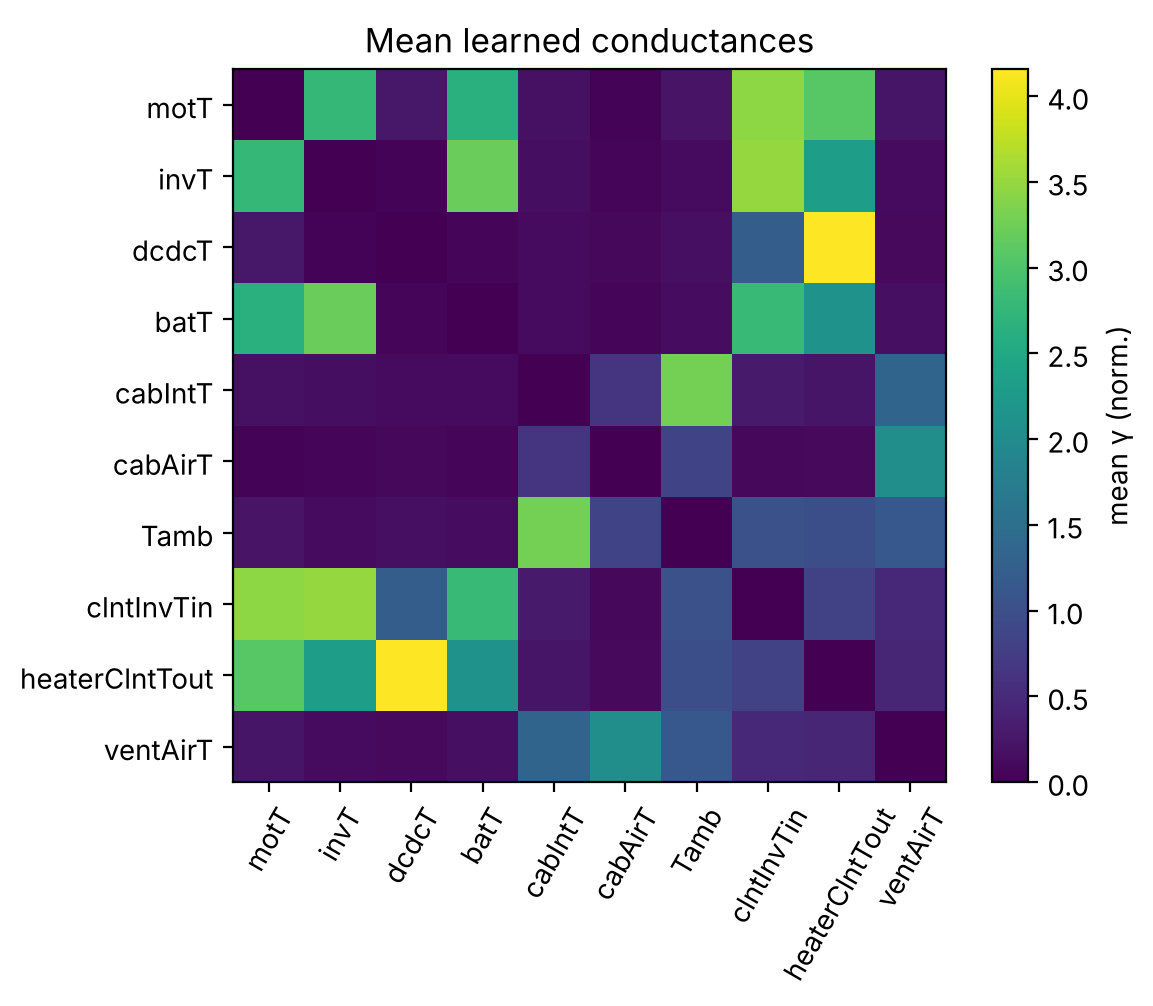

In [12]:
# Which node pairs exchange the most heat? Average learned conductance over the -7 °C cycle.
# Bright squares = strong thermal links. Weak links could be removed (paper Sec. 3.3).
with torch.no_grad():
    x, gs = Xte[:, 0], []
    for k in range(Xte.shape[1] - 1):
        x, g = model.cell(x, Bte[:, k], Ote[:, k]); gs.append(g)
    g_mean = torch.cat(gs).mean(0)
ALL = NODE_NAMES + BND_NAMES
Gm = model.cell.conductance_matrix(g_mean[None])[0].numpy()
plt.figure(figsize=(6, 5)); plt.imshow(Gm, cmap="viridis"); plt.colorbar(label="mean γ (norm.)")
plt.xticks(range(len(ALL)), ALL, rotation=60); plt.yticks(range(len(ALL)), ALL); plt.title("Mean learned conductances")
plt.tight_layout()

torch.save(model.state_dict(), "tnn_partA.pt"); print("saved tnn_partA.pt")   # keep the trained model

## 5. Part B: γ-network → COM → HFM (our actual method)

This is the method Prashant asked for: **end-to-end training through the COM**. A network looks at the
operating point and outputs the COM's 11 multipliers γ; the COM predicts 30 s ahead with them; the error
against the HFM is back-propagated **through the COM** into the network.

**Set up exactly like the NMPC uses the COM**, so the result carries over to the controller:
- every 30-s window starts from the HFM state (in the NMPC: the measured state);
- γ is computed **once at the window start and held for 30 s** (like `prepParaVec` in the NMPC);
- refrigerant/air properties (CoolProp) and supervisor commands are computed at the window start and held;
- inputs (compressor, blower, pumps, heater) and heat loads vary over the window (the NMPC knows them);
- RK4 with 1-s steps.

**What the network sees** (at the window start): ambient temperature, the 9 states, the 6 inputs now and their
30-s average, and motor / inverter heat and battery current.

**Compared against**
- **γ = 1**: the nominal COM;
- **interpolation table**: γ from `tunedVariables` (what the NMPC uses today, `prepParaVec`);
- **one constant γ**: a single γ vector trained the same way. This shows whether the network's dependence on
  the operating point matters, or whether simply re-tuning one parameter set would do.

**Data**: all 9 ambient temperatures (old files −5, −7, −10 °C, new exports 0, −12, −15, −20, −25, −30 °C).
Train on 0, −5, −10, −15, −20, −30 °C; test on the **unseen −7, −12, −25 °C**. All are the same drive cycle.
To treat old and new files the same way, and the same way the NMPC runs the COM:
- supervisor commands come from a port of `thermalLogicAndEstimation.m` (in cold weather: heat-pump mode once
  the compressor runs, serial coolant loops). The old files' stored commands came from an older logic;
- superheat is the NMPC's fixed 2 K (`MPCController_step_coreLQRNew.m`); the new export has no superheat;
- the first 60 s of every run are skipped (compressor start-up; at 0 °C the pressure briefly exceeds R134a's
  critical pressure).

**Loss**: each state's error is divided by the nominal COM's error for that state ("balanced"), so no state
can be traded away: with plain units (1 K = 1 bar) the battery got worse than with γ = 1.

**Helper files in this folder**
- `com_torch.py`: the COM in PyTorch, checked against MATLAB to ~1e-12 (`test_com_port.py`)
- `est_coolprop.py`: `estimateParameters.m` in Python. Needs `pip install CoolProp`.
- `partB.py`: data, baselines, γ network, training

In [13]:
# Part B works in float64 (pressures are ~1e6 Pa). First run: ~2 min for CoolProp (9 x 3601 s), then cached in _cache/.
import importlib, partB
importlib.reload(partB)
from partB import *

CACHE = Path("_cache"); CACHE.mkdir(exist_ok=True)
PB = load_all_profiles(DATA, RESULTS, CACHE)                          # HFM states in COM units (K, Pa), keys = |Tamb|
table = TableGamma(DATA / "tunedVariables_minus5_minus10.mat")        # today's interpolation table
print("profiles:", list(PB))

TRAIN_B, TEST_B = (0, 5, 10, 15, 20, 30), (7, 12, 25)
train_w = cat_windows([make_windows(PB[T], stride=5) for T in TRAIN_B])   # a window every 5 s (overlapping)
test_w  = {T: make_windows(PB[T], stride=30) for T in PB}                 # a window every 30 s, all temperatures

z = features(train_w); MU, SD = z.mean(0), z.std(0) + 1e-6             # normalise network inputs
norm = lambda z: (z - MU) / SD
LOSS_SCALE = nominal_scale(subset(train_w, torch.arange(0, train_w["x0"].shape[0], 4)))   # balanced loss
print("training windows:", train_w["x0"].shape[0], "| test windows per temperature:", len(test_w[7]["k0"]))

profiles: [0, 5, 7, 10, 12, 15, 20, 25, 30]


training windows: 4218 | test windows per temperature: 118


γ network:


iter    0  loss   1.0067  lr 3.0e-03      1s


iter   50  loss   0.4003  lr 1.5e-03     32s


iter  100  loss   0.3399  lr 3.8e-04     64s


iter  150  loss   0.3649  lr 1.9e-04     96s


iter  200  loss   0.3368  lr 2.3e-05    128s


... (3 outputs left out)

iter    0  loss   1.0067  lr 3.0e-02      0s


iter   50  loss   0.5827  lr 1.5e-02     31s


iter  100  loss   0.4764  lr 3.7e-03     64s


iter  149  loss   0.5053  lr 9.4e-04     95s


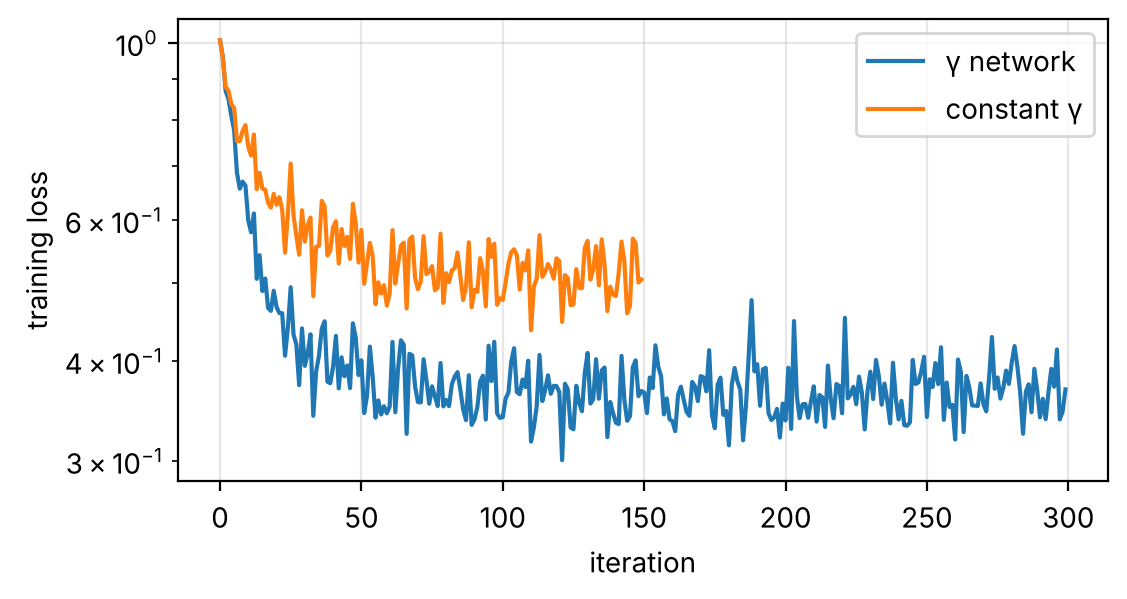

In [14]:
# Train the γ network (~4 min) and, for comparison, one constant γ vector (~2 min).
gamma_net = GammaNet()                       # starts at γ = 1
print("γ network:")
hist = train_gamma(gamma_net, train_w, norm, iters=300, log_every=50, loss_scale=LOSS_SCALE)

const_gamma = ConstantGamma()
print("\none constant γ:")
hist_c = train_gamma(const_gamma, train_w, norm, iters=150, lr=3e-2, log_every=50, loss_scale=LOSS_SCALE)

torch.save(dict(state=gamma_net.state_dict(), mu=MU, sd=SD), "gammanet_partB.pt")
plt.figure(figsize=(6, 3)); plt.semilogy(hist, label="γ network"); plt.semilogy(hist_c, label="constant γ")
plt.xlabel("iteration"); plt.ylabel("training loss"); plt.legend(); plt.grid(alpha=.3)


Tamb = -0 °C (train)         motT [K]     invT [K]    dcdcT [K]     batT [K]   p_in [bar]  p_out [bar]  cabIntT [K]  cabAirT [K]
  γ = 1                      0.272        0.645        0.321        0.043        0.025        2.856        0.159        0.234
  table                      0.173        0.328        0.316        0.087        0.027        1.413        0.408        0.588
  constant γ                 0.133        0.166        0.322        0.025        0.025        0.686        0.030        0.176
  γ network                  0.079        0.100        0.296        0.017        0.025        0.526        0.010        0.034

Tamb = -5 °C (train)         motT [K]     invT [K]    dcdcT [K]     batT [K]   p_in [bar]  p_out [bar]  cabIntT [K]  cabAirT [K]
  γ = 1                      0.310        0.763        0.524        0.036        0.019        5.107        0.214        0.299
  table                      0.256        0.331        0.501        0.063        0.020        1.306        0.6

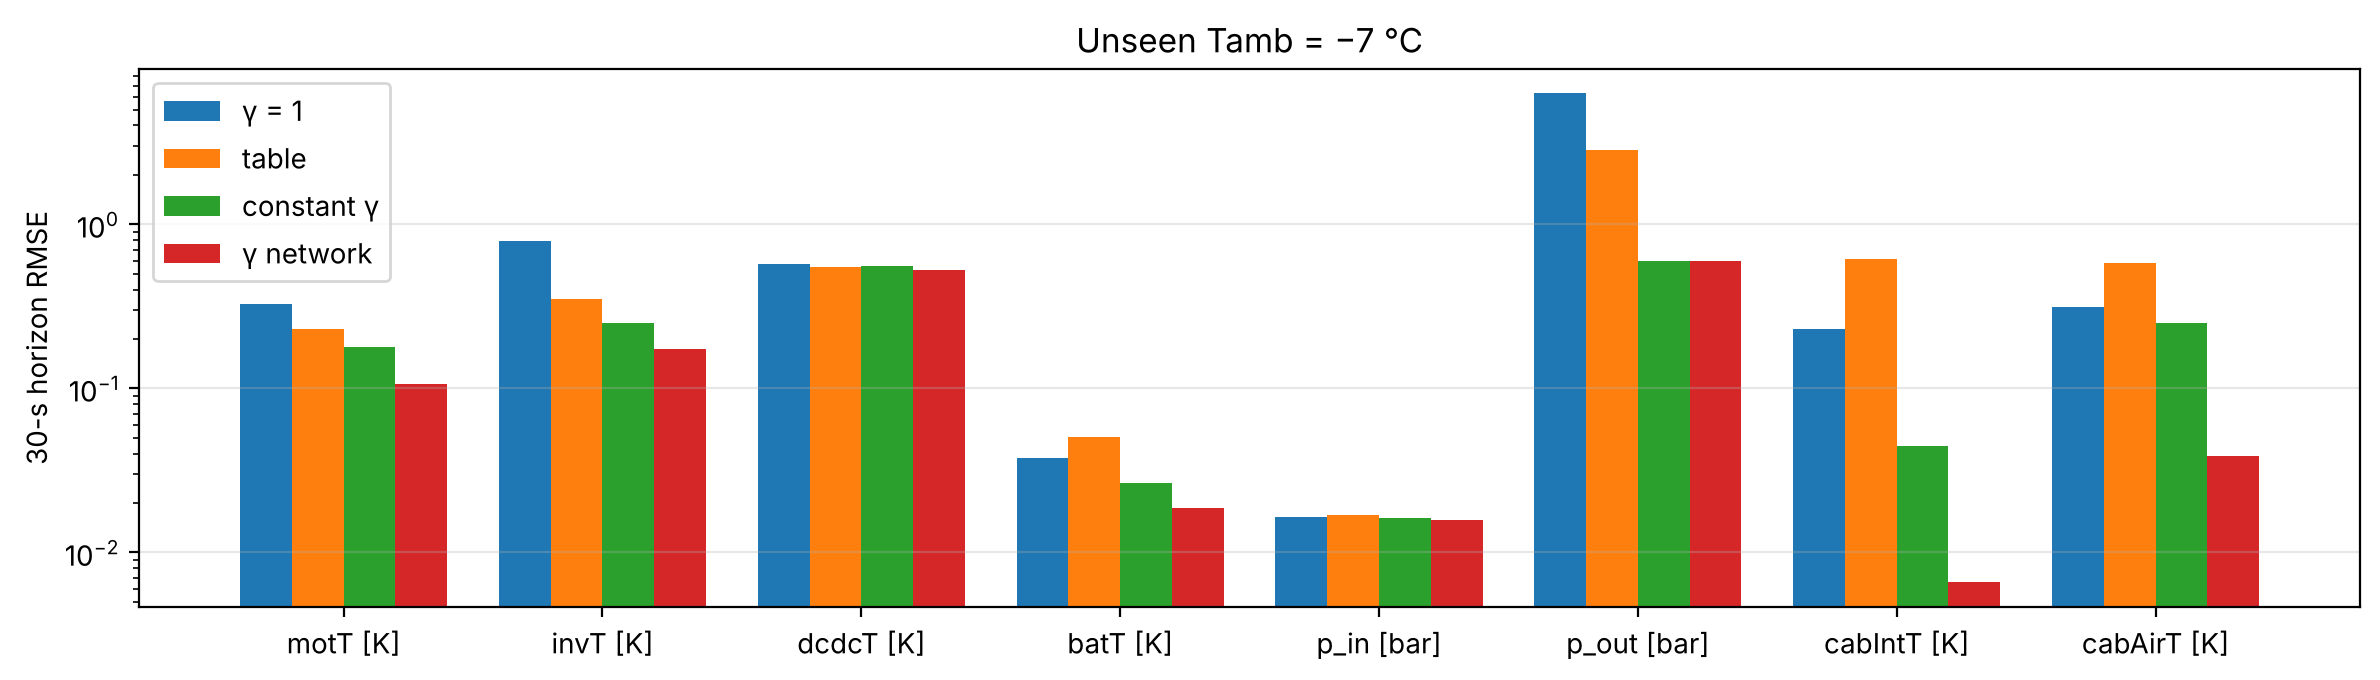

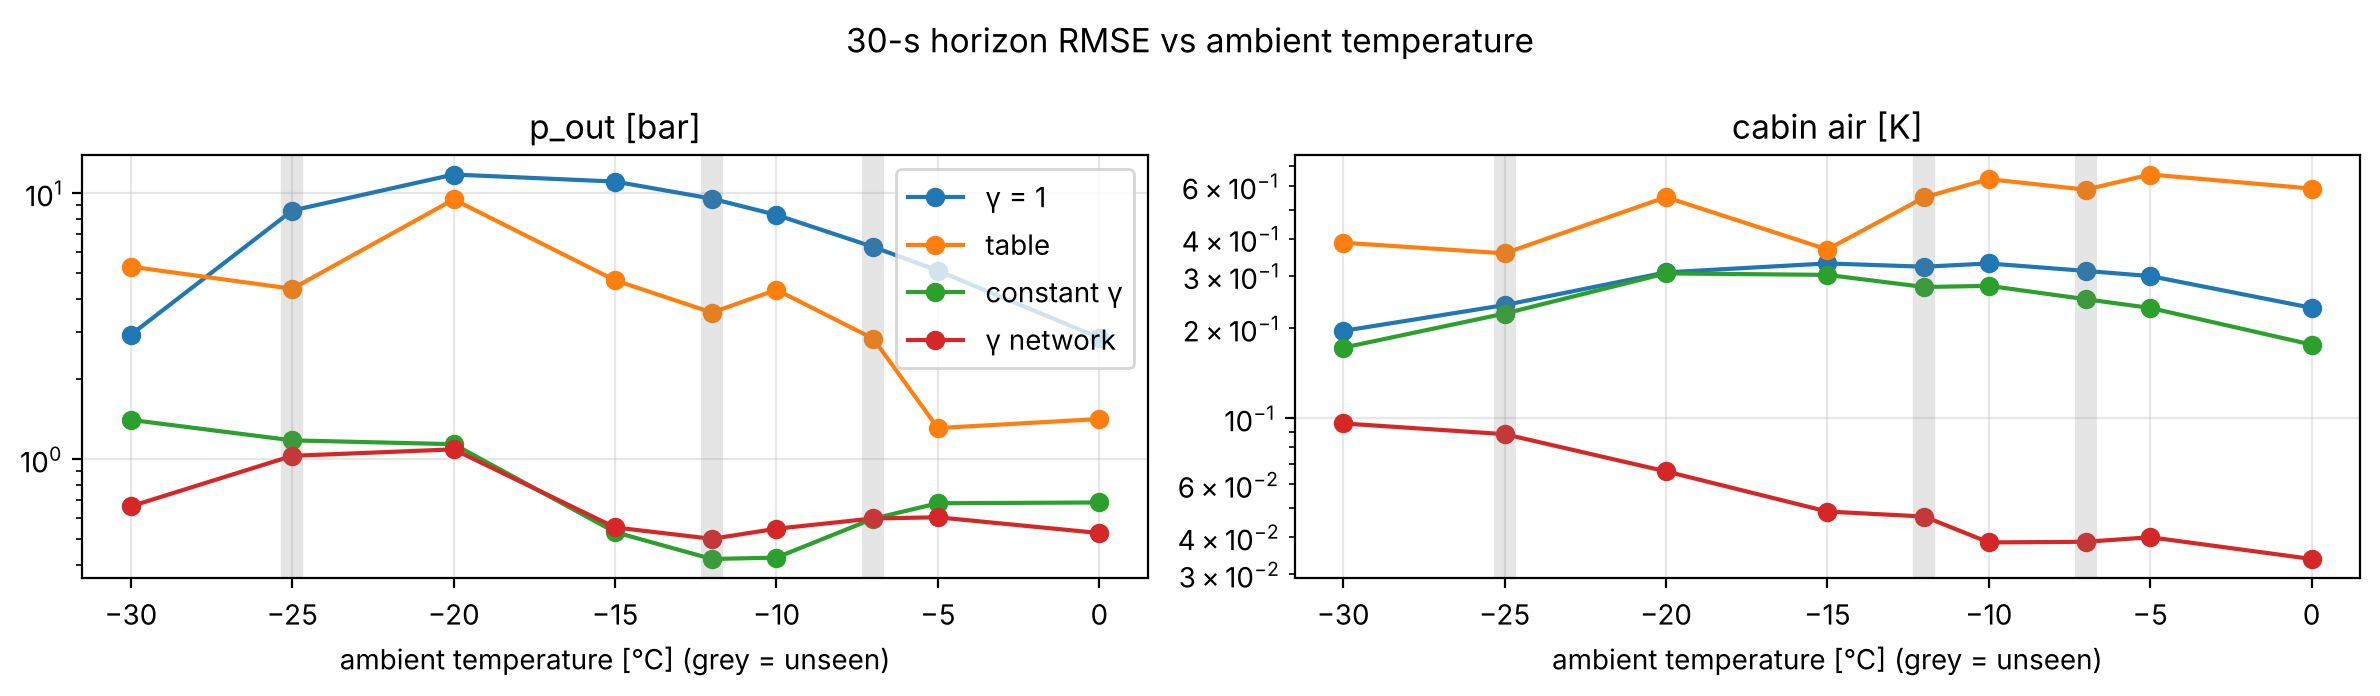

In [15]:
# 30-s horizon RMSE per state: γ = 1 vs interpolation table vs constant γ vs γ network
REPORT = [0, 1, 2, 4, 5, 6, 7, 8]                       # skip SOC (no γ acts on it, error ~1e-5)
LABELS = ["motT [K]", "invT [K]", "dcdcT [K]", "batT [K]", "p_in [bar]", "p_out [bar]", "cabIntT [K]", "cabAirT [K]"]

results = {}
with torch.no_grad():
    for T, w in test_w.items():
        W = len(w["k0"])
        results[T] = evaluate(w, {
            "γ = 1": torch.ones(W, 11, dtype=DT),
            "table": table(w["Tamb"].numpy(), w["x0"].numpy()),
            "constant γ": const_gamma(norm(features(w))),
            "γ network": gamma_net(norm(features(w))),
        })

for T in test_w:
    tag = "UNSEEN" if T in TEST_B else "train"
    print(f"\nTamb = -{T} °C ({tag})      " + "  ".join(f"{l:>11s}" for l in LABELS))
    for name, r in results[T].items():
        print(f"  {name:12s}         " + "  ".join(f"{r[i].item():11.3f}" for i in REPORT))

fig, ax = plt.subplots(figsize=(12, 3.5))
names = list(results[7]); wbar = 0.2
for j, name in enumerate(names):
    ax.bar(np.arange(len(REPORT)) + (j - 1.5) * wbar, [results[7][name][i].item() for i in REPORT], wbar, label=name)
ax.set_xticks(range(len(REPORT))); ax.set_xticklabels(LABELS); ax.set_yscale("log"); ax.grid(alpha=.3, axis="y")
ax.set_ylabel("30-s horizon RMSE"); ax.set_title("Unseen Tamb = −7 °C"); ax.legend(); plt.tight_layout()

# Compressor outlet pressure and cabin air error over all 9 temperatures
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
Ts = list(test_w)
for a, i, lab in [(ax[0], 6, "p_out [bar]"), (ax[1], 8, "cabin air [K]")]:
    for name in names:
        a.plot([-T for T in Ts], [results[T][name][i].item() for T in Ts], "o-", label=name)
    for T in TEST_B: a.axvline(-T, color="grey", alpha=.2, lw=8)
    a.set_yscale("log"); a.set_xlabel("ambient temperature [°C] (grey = unseen)"); a.set_title(lab); a.grid(alpha=.3)
ax[0].legend(); fig.suptitle("30-s horizon RMSE vs ambient temperature"); plt.tight_layout()

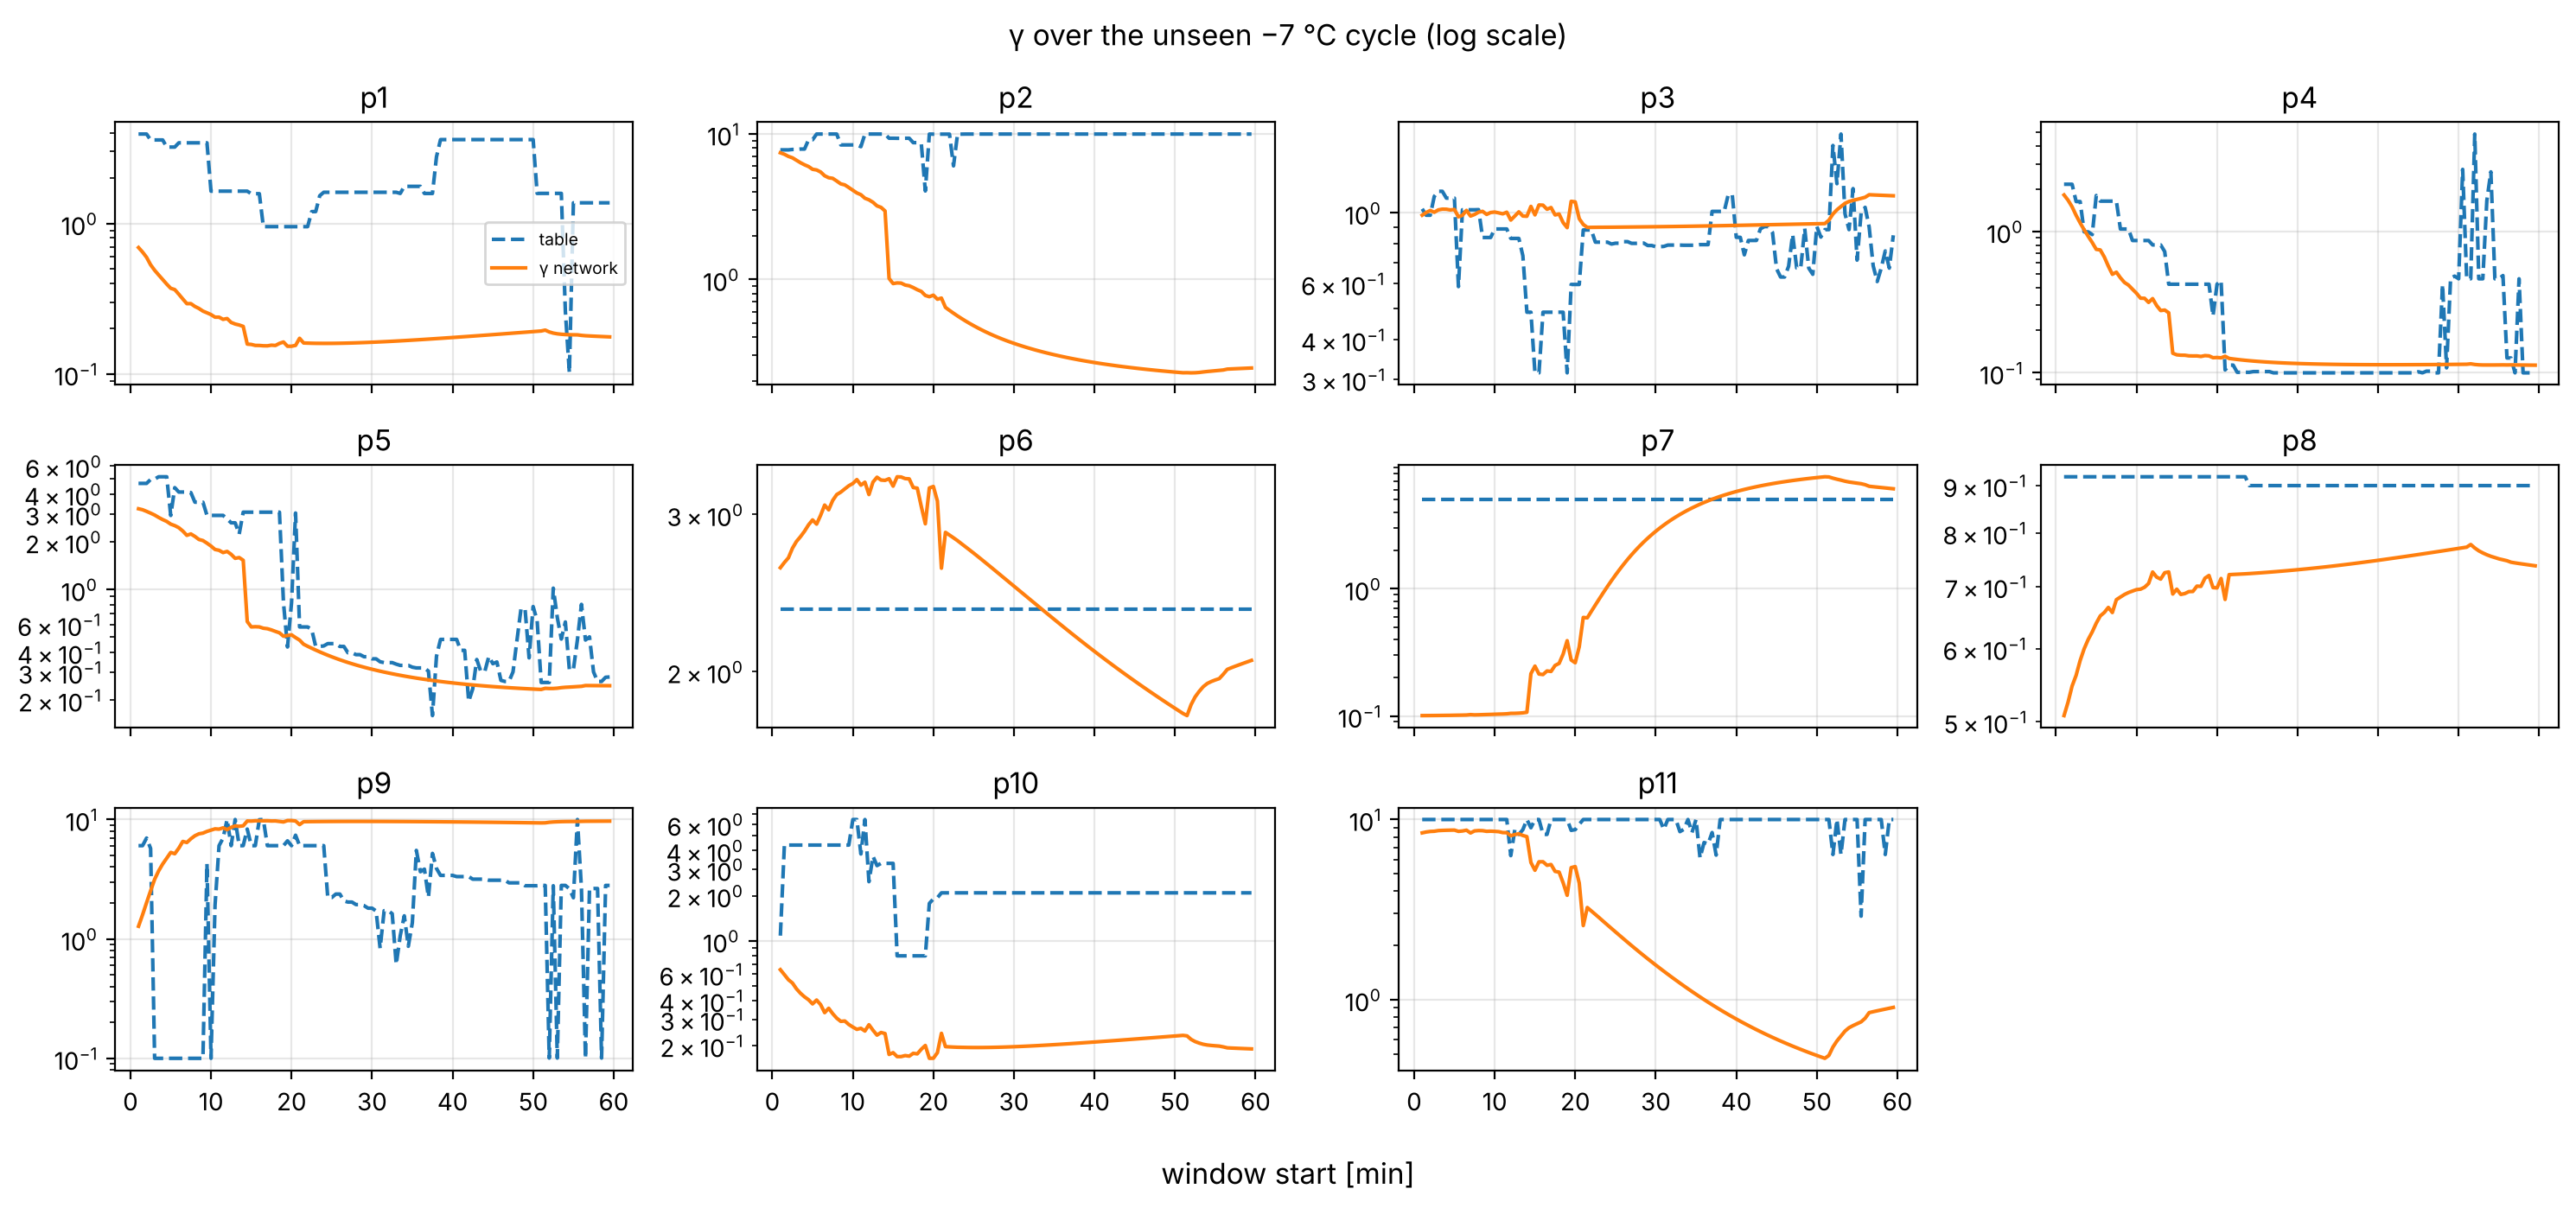

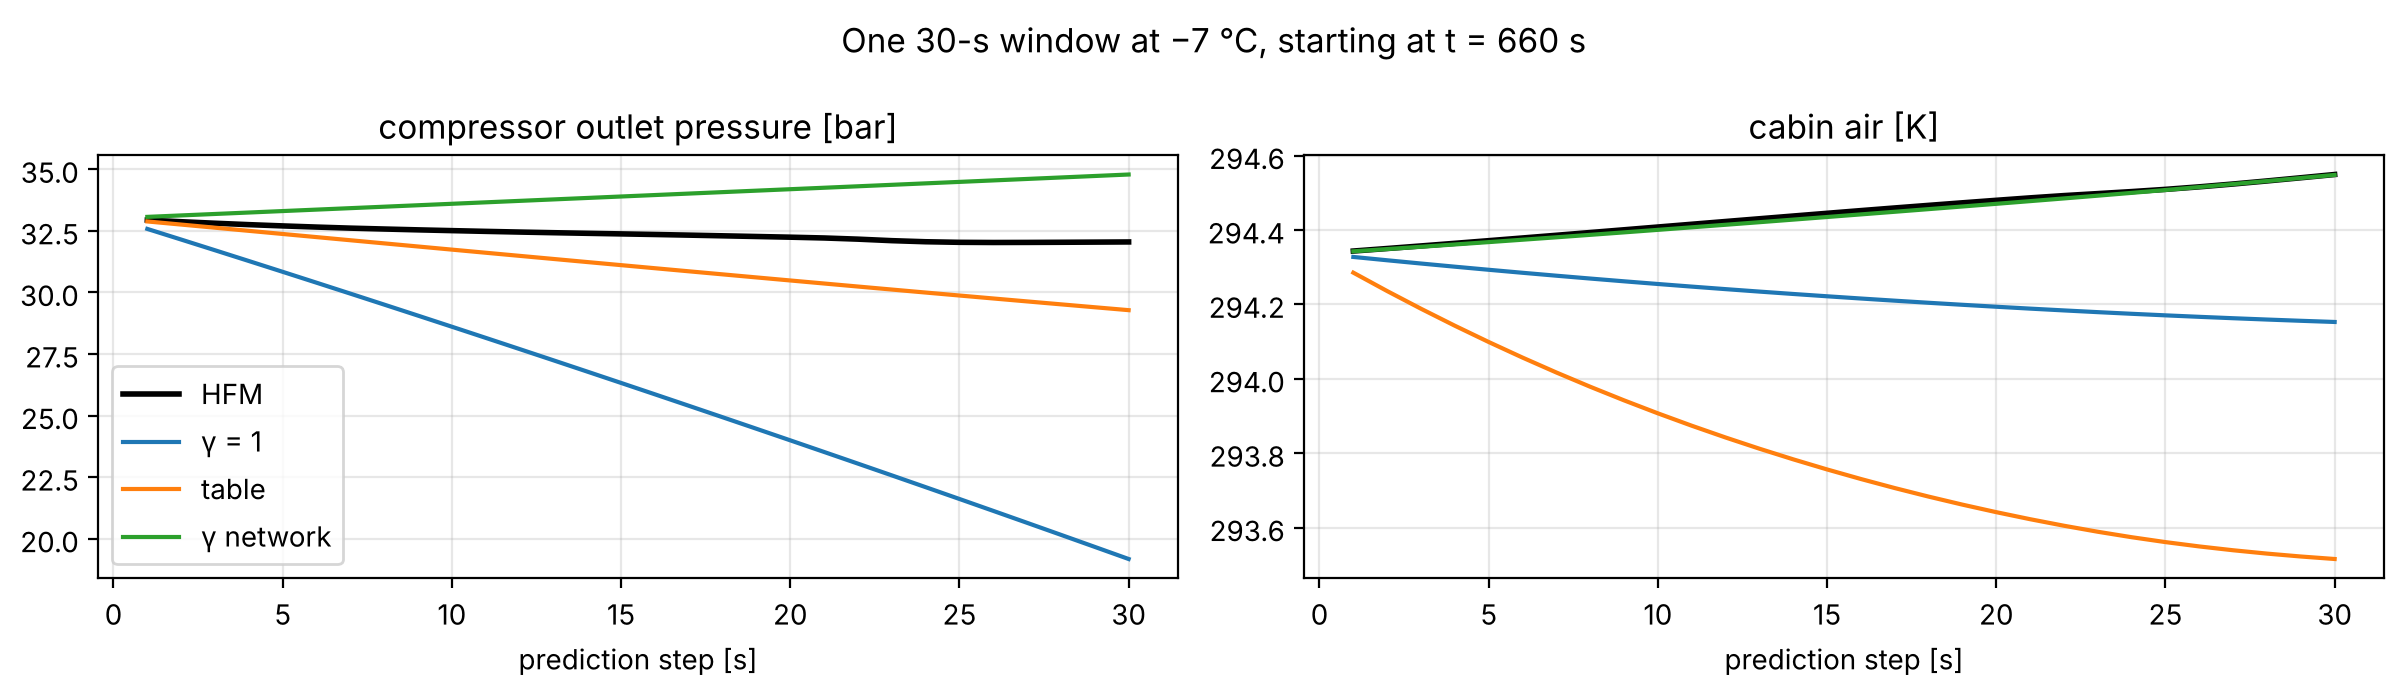

In [16]:
# What the γ network does over the −7 °C cycle, and one example 30-s window
w = test_w[7]
with torch.no_grad():
    g_net = gamma_net(norm(features(w))).numpy()
    g_tab = table(w["Tamb"].numpy(), w["x0"].numpy()).numpy()

fig, ax = plt.subplots(3, 4, figsize=(15, 7), sharex=True)
for i, a in enumerate(ax.flat[:11]):
    a.plot(w["k0"] / 60, g_tab[:, i], "--", label="table")
    a.plot(w["k0"] / 60, g_net[:, i], label="γ network")
    a.set_yscale("log"); a.set_title(f"p{i+1}"); a.grid(alpha=.3)
ax.flat[0].legend(fontsize=7); ax.flat[11].axis("off")
fig.supxlabel("window start [min]"); fig.suptitle("γ over the unseen −7 °C cycle (log scale)"); plt.tight_layout()

# example window: compressor outlet pressure and cabin air over 30 s
j = 20                                                   # window starting at 10 min
one = subset(w, torch.tensor([j]))
with torch.no_grad():
    preds = {"γ = 1": simulate(one, torch.ones(1, 11, dtype=DT)),
             "table": simulate(one, table(one["Tamb"].numpy(), one["x0"].numpy())),
             "γ network": simulate(one, gamma_net(norm(features(one))))}
t = np.arange(1, one["x_true"].shape[1] + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for a, i, scale, lab in [(ax[0], 6, 1e5, "compressor outlet pressure [bar]"), (ax[1], 8, 1, "cabin air [K]")]:
    a.plot(t, one["x_true"][0, :, i] / scale, "k", lw=2, label="HFM")
    for name, p in preds.items():
        a.plot(t, p[0, :, i] / scale, label=name)
    a.set_xlabel("prediction step [s]"); a.set_title(lab); a.grid(alpha=.3)
ax[0].legend(); fig.suptitle(f"One 30-s window at −7 °C, starting at t = {int(one['k0'][0])} s"); plt.tight_layout()

### What these results do and do not show

- The test temperatures (−7, −12, −25 °C) were never used for training, but it is the **same drive cycle** as
  the training data. Held-out drive cycles are still needed (agreed evaluation plan).
- The new exports define `cabIntT` as a plain average of glass/doors/roof; the COM's cabin interior is one
  mass. Fixing that needs the wall temperatures, i.e. re-running the simulations with an updated export (the
  saved simlogs cannot be reopened).
- The interpolation table is rebuilt here with SciPy (`LinearNDInterpolator`), the same idea as MATLAB's
  `scatteredInterpolant`; its values can differ slightly from MATLAB's.
- γ is held for 30 s like in the NMPC. The final check is closed-loop NMPC energy and comfort (January).
- Superheat is fixed at 2 K like in the NMPC; the real superheat would need it in the export.